In [1]:
import pandas as pd
import json
import numpy as np
import ast
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import re

# Load the data
df = pd.read_parquet('decompose/train-00000-of-00001.parquet')
df.shape

(773, 1)

In [4]:
df

,conversations
0,[{'content': 'You are a helpful assistant that...
1,[{'content': 'You are a helpful assistant that...
2,[{'content': 'You are a helpful assistant that...
3,[{'content': 'You are a helpful assistant that...
4,[{'content': 'You are a helpful assistant that...
...,...
768,[{'content': 'You are an expert at Vietnamese ...
769,[{'content': 'You are an expert at Vietnamese ...
770,[{'content': 'You are an expert at Vietnamese ...
771,[{'content': 'You are an expert at Vietnamese ...


In [59]:
user_query = []
analysis = []
decomposed_query = []
for i in range(0, len(df)):
    rows = df.iloc[i, 0]
    user_query.append(rows[1]['content'])
    chatbot_response = rows[2]['content']
    split_index = chatbot_response.find("[")
    analysis_part = chatbot_response[:split_index].strip()
    if analysis_part == "":
        list_string = chatbot_response[0] + "\'" + chatbot_response[1:-1] + "\'" + chatbot_response[-1]
        decomposed_query_part = ast.literal_eval(list_string)
    else:
        decomposed_query_part = ast.literal_eval(chatbot_response[split_index:])

    analysis.append(analysis_part)
    decomposed_query.append(decomposed_query_part)


In [60]:
len(user_query), len(analysis), len(decomposed_query)

(773, 773, 773)

In [61]:
df_new = pd.DataFrame({
    "user_query": user_query,
    "analysis": analysis,
    "decomposed_query": decomposed_query
})
df_new.to_csv("processed_decompose.csv", index=False, encoding="utf-8")

In [67]:
df_new

,user_query,analysis,decomposed_query
0,Tôi đang phân vân về cách thức đảm bảo quyền l...,Câu hỏi này cần được phân tích thành các khía ...,[Nhà tuyển dụng có trách nhiệm gì trong việc đ...
1,Có cách nào để các cơ quan nhà nước và tổ chức...,"Để trả lời câu hỏi này, chúng ta cần khám phá ...",[Các cơ quan nhà nước cần thực hiện những bước...
2,Tôi muốn biết các biện pháp nào cần thiết để g...,Câu hỏi này yêu cầu chúng ta phân tích nhiều y...,[Nhà trường cần làm gì để đảm bảo bình đẳng gi...
3,"Trong bối cảnh việc làm, các doanh nghiệp phải...",Câu hỏi này yêu cầu chúng ta xem xét cả trách ...,[Doanh nghiệp có thể áp dụng những chính sách ...
4,Tôi muốn biết cách thức nào mà chính quyền có ...,"Để hiểu rõ cách thức huy động sự tham gia, câu...",[Chính quyền có thể thực hiện các chiến dịch n...
...,...,...,...
768,Cần có những biện pháp gì để kiểm soát nội dun...,,[Làm thế nào để kiểm soát nội dung truyền thôn...
769,Có những yêu cầu gì cần tuân thủ khi phát hành...,,[Yêu cầu nào cần thiết khi xuất bản sản phẩm d...
770,Có những điều kiện nào cần được xem xét để xác...,,[Nội dung nào được coi là có lợi cho trẻ em tr...
771,Làm thế nào để tổ chức các hoạt động giáo dục ...,,[Hoạt động giáo dục cho trẻ em cần được tổ chứ...


In [121]:
stats = {
    "Tổng số dòng": 773,
    "Độ dài trung bình user_query": df_new["user_query_length"].mean(),
    "Độ dài trung bình analysis": df_new["analysis_length"].mean(),
    "Số câu decomposed trung bình": df_new["num_decomposed_queries"].mean(),
    "Số câu decomposed lớn nhất": df_new["num_decomposed_queries"].max(),
}

report_df = pd.DataFrame(stats.items(), columns=["Chỉ số", "Giá trị"])
report_df

,Chỉ số,Giá trị
0,Tổng số dòng,773.000000
1,Độ dài trung bình user_query,99.760673
2,Độ dài trung bình analysis,84.571798
3,Số câu decomposed trung bình,1.972833
4,Số câu decomposed lớn nhất,7.000000


In [71]:
df_new["user_query_length"] = df_new["user_query"].astype(str).apply(len)
df_new["analysis_length"] = df_new["analysis"].astype(str).apply(len)
df_new["num_decomposed_queries"] = df_new["decomposed_query"].astype(str).apply(lambda x: x.count(",") + 1 if x != "[]" else 0)

In [72]:
df_new

,user_query,analysis,decomposed_query,user_query_length,analysis_length,num_decomposed_queries
0,Tôi đang phân vân về cách thức đảm bảo quyền l...,Câu hỏi này cần được phân tích thành các khía ...,[Nhà tuyển dụng có trách nhiệm gì trong việc đ...,263,341,3
1,Có cách nào để các cơ quan nhà nước và tổ chức...,"Để trả lời câu hỏi này, chúng ta cần khám phá ...",[Các cơ quan nhà nước cần thực hiện những bước...,153,247,3
2,Tôi muốn biết các biện pháp nào cần thiết để g...,Câu hỏi này yêu cầu chúng ta phân tích nhiều y...,[Nhà trường cần làm gì để đảm bảo bình đẳng gi...,178,238,3
3,"Trong bối cảnh việc làm, các doanh nghiệp phải...",Câu hỏi này yêu cầu chúng ta xem xét cả trách ...,[Doanh nghiệp có thể áp dụng những chính sách ...,156,211,3
4,Tôi muốn biết cách thức nào mà chính quyền có ...,"Để hiểu rõ cách thức huy động sự tham gia, câu...",[Chính quyền có thể thực hiện các chiến dịch n...,151,216,3
...,...,...,...,...,...,...
768,Cần có những biện pháp gì để kiểm soát nội dun...,,[Làm thế nào để kiểm soát nội dung truyền thôn...,83,0,1
769,Có những yêu cầu gì cần tuân thủ khi phát hành...,,[Yêu cầu nào cần thiết khi xuất bản sản phẩm d...,77,0,1
770,Có những điều kiện nào cần được xem xét để xác...,,[Nội dung nào được coi là có lợi cho trẻ em tr...,99,0,1
771,Làm thế nào để tổ chức các hoạt động giáo dục ...,,[Hoạt động giáo dục cho trẻ em cần được tổ chứ...,78,0,1


In [ ]:
stats = {
    "Tổng số dòng": 773,
    "Độ dài trung bình user_query": df_new["user_query_length"].mean(),
    "Độ dài trung bình analysis": df_new["analysis_length"].mean(),
    "Số câu decomposed trung bình": df_new["num_decomposed_queries"].mean(),
    "Số câu decomposed lớn nhất": df_new["num_decomposed_queries"].max(),
}

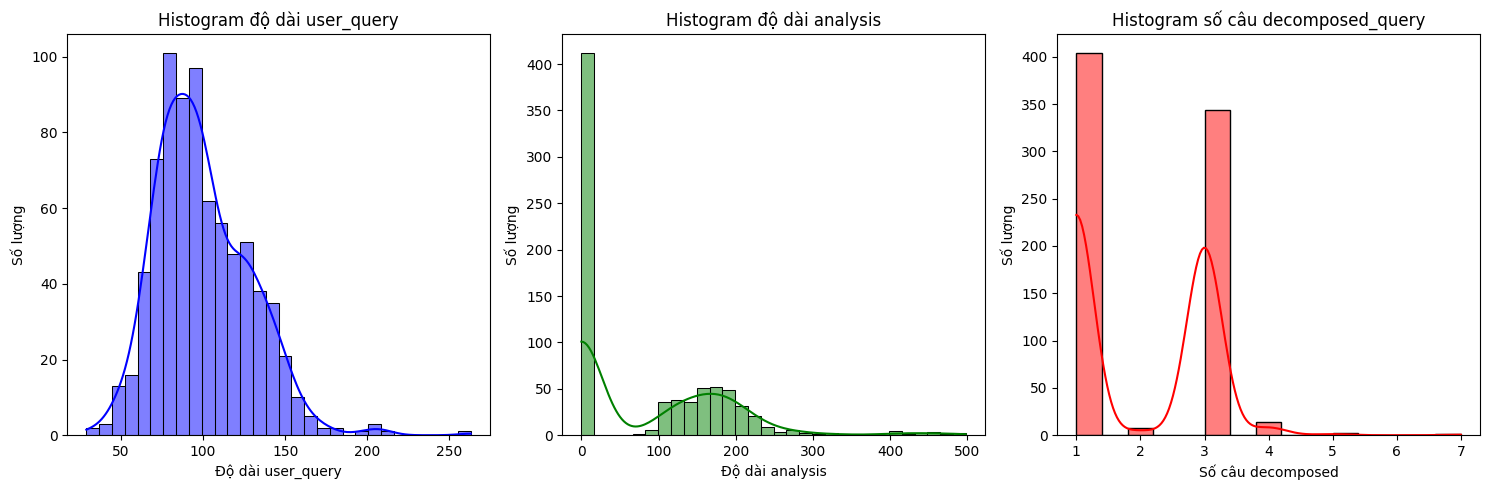

In [ ]:
import seaborn as sns

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(df_new["user_query_length"], bins=30, kde=True, color="blue")
plt.xlabel("Độ dài user_query")
plt.ylabel("Số lượng")
plt.title("Histogram độ dài user_query")

plt.subplot(1, 3, 2)
sns.histplot(df_new["analysis_length"], bins=30, kde=True, color="green")
plt.xlabel("Độ dài analysis")
plt.ylabel("Số lượng")
plt.title("Histogram độ dài analysis")

plt.subplot(1, 3, 3)
sns.histplot(df_new["num_decomposed_queries"], bins=15, kde=True, color="red")
plt.xlabel("Số câu decomposed")
plt.ylabel("Số lượng")
plt.title("Histogram số câu decomposed_query")

plt.tight_layout()
plt.show()

In [76]:
from pyvi import ViTokenizer
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

In [ ]:
with open("vietnamese-stopwords.txt", "r", encoding="utf-8") as f:
    vietnamese_stopwords = set(f.read().splitlines())

print(len(vietnamese_stopwords))

1942


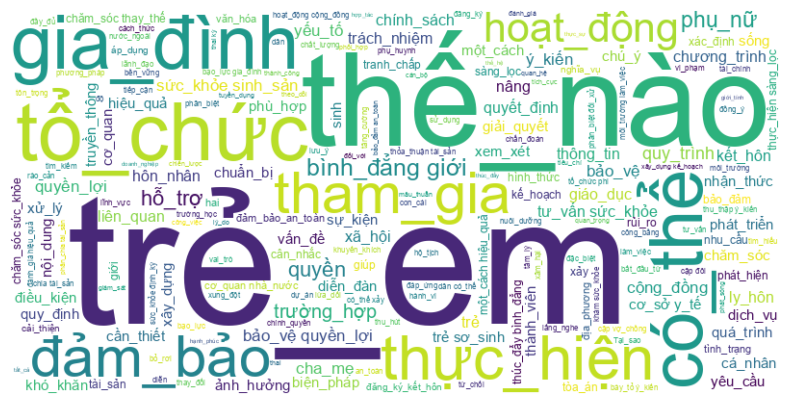

In [ ]:
text = " ".join(df_new["user_query"].astype(str))
tokenized_text = ViTokenizer.tokenize(text)
wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color="white", 
    stopwords=vietnamese_stopwords,
    font_path="arial.ttf"
).generate(tokenized_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

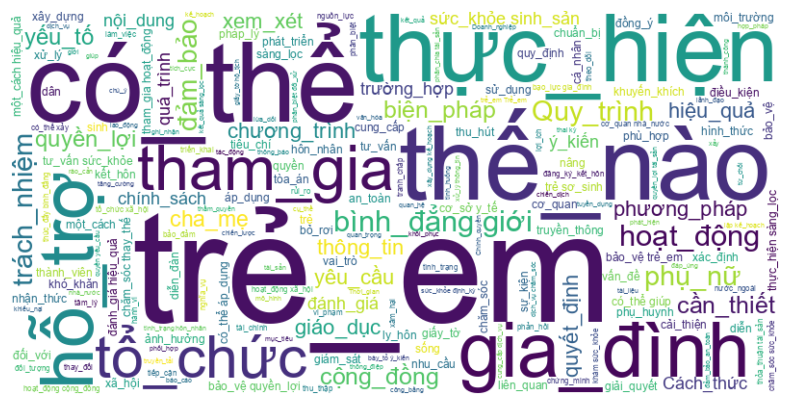

In [ ]:
text_decomposed = " ".join([" ".join(q) for q in df_new["decomposed_query"]])

tokenized_text_decomposed = ViTokenizer.tokenize(text_decomposed)

wordcloud_decomposed = WordCloud(
    width=800, 
    height=400, 
    background_color="white", 
    stopwords=vietnamese_stopwords, 
    font_path="arial.ttf" 
).generate(tokenized_text_decomposed)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_decomposed, interpolation="bilinear")
plt.axis("off")
plt.show()

In [ ]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("dangvantuan/vietnamese-document-embedding", trust_remote_code=True)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

c:\Users\Phuong\.conda\envs\pytorch-gpu\Lib\site-packages\huggingface_hub\file_download.py:142: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Phuong\.cache\huggingface\hub\models--dangvantuan--vietnamese-document-embedding. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/171 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/6.09k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

...

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.34k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

In [ ]:
def calculate_similarity(user_query, decomposed_queries):
    user_embedding = model.encode(user_query)
    user_embedding = np.array(user_embedding).reshape(1, -1)
    
    decomposed_embeddings = model.encode(decomposed_queries)
    decomposed_embeddings = np.array(decomposed_embeddings).reshape(1, -1)
    similarities = cosine_similarity(user_embedding, decomposed_embeddings)
    
    return similarities

In [97]:
similarity_scores = []
for i in range(len(df_new)):
    user_query = df_new.iloc[i]['user_query']
    decomposed_queries = df_new.iloc[i]['decomposed_query']
    similarity_list = []
    if decomposed_queries != []:
        similarity_list = [calculate_similarity(user_query, decomposed_query) for decomposed_query in decomposed_queries]
    similarity_score = sum(similarity_list) / len(similarity_list) if similarity_list != [] else 0
    similarity_scores.append(similarity_score)

In [109]:
similarity_scores = [score.item() for score in similarity_scores]
similarity_scores[:5]

[0.7153376936912537,
 0.6960565447807312,
 0.7602301239967346,
 0.8174853324890137,
 0.8503713607788086]

In [110]:
df_new["similarity_score"] = similarity_scores

In [112]:
df_new.head()

,user_query,analysis,decomposed_query,user_query_length,analysis_length,num_decomposed_queries,similarity_score
0,Tôi đang phân vân về cách thức đảm bảo quyền l...,Câu hỏi này cần được phân tích thành các khía ...,[Nhà tuyển dụng có trách nhiệm gì trong việc đ...,263,341,3,0.715338
1,Có cách nào để các cơ quan nhà nước và tổ chức...,"Để trả lời câu hỏi này, chúng ta cần khám phá ...",[Các cơ quan nhà nước cần thực hiện những bước...,153,247,3,0.696057
2,Tôi muốn biết các biện pháp nào cần thiết để g...,Câu hỏi này yêu cầu chúng ta phân tích nhiều y...,[Nhà trường cần làm gì để đảm bảo bình đẳng gi...,178,238,3,0.760230
3,"Trong bối cảnh việc làm, các doanh nghiệp phải...",Câu hỏi này yêu cầu chúng ta xem xét cả trách ...,[Doanh nghiệp có thể áp dụng những chính sách ...,156,211,3,0.817485
4,Tôi muốn biết cách thức nào mà chính quyền có ...,"Để hiểu rõ cách thức huy động sự tham gia, câu...",[Chính quyền có thể thực hiện các chiến dịch n...,151,216,3,0.850371


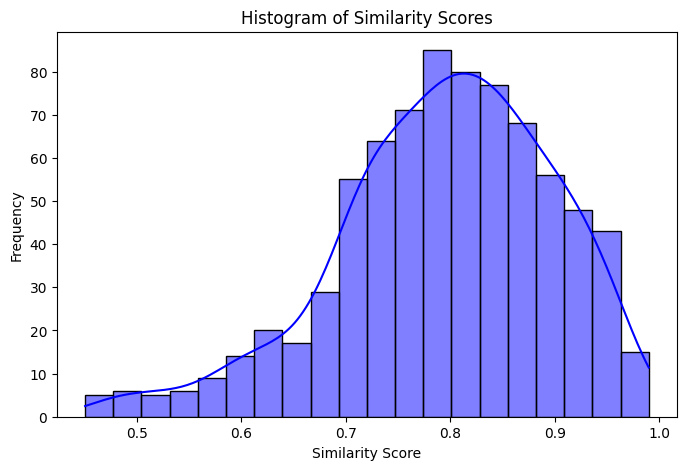

In [113]:
plt.figure(figsize=(8, 5))
sns.histplot(df_new["similarity_score"], bins=20, kde=True, color="blue")
plt.xlabel("Similarity Score")
plt.ylabel("Frequency")
plt.title("Histogram of Similarity Scores")
plt.show()

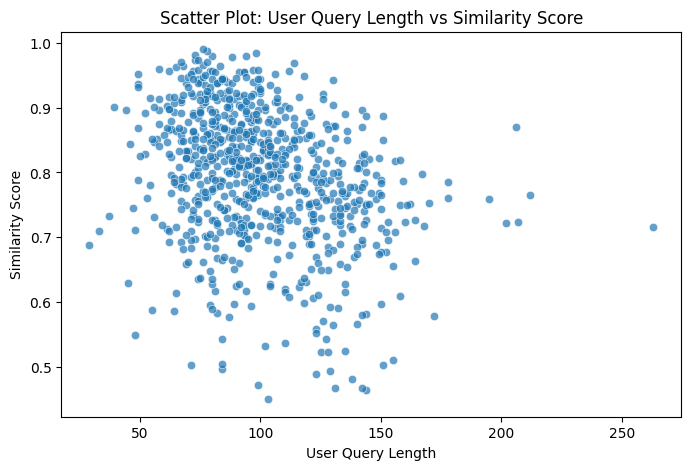

In [116]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df_new["user_query_length"], y=df_new["similarity_score"], alpha=0.7)
plt.xlabel("User Query Length")
plt.ylabel("Similarity Score")
plt.title("Scatter Plot: User Query Length vs Similarity Score")
plt.show()
